Title: VRES_Detection_cc.ipynb

Purpose: Identifiy Low Energy Events with varying lengths from the model output data

Author: Onno Nennecke on 21.03.2025 Modified: 10.09.2025

Input data: 

- final model output
    - This file lies here: '/climca/people/onennecke/model_output/not_bias_corrected/model_output_all.nc'

Output data:

- LEE Tables: LEE_dat_14.csv, LEE_dat_7.csv, LEE_dat.csv, LEE_dat_14_selection.csv, LEE_dat_7_selection.csv, LEE_vl.csv
    - This file lies here: '/climca/people/onennecke/model_output/LEE_detection/'

In [1]:
# Importing libraries
import xarray as xr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.ndimage as ndimage
import os
import glob


### Read Model output data

In [2]:
path = '/climca/people/onennecke/model_output/not_bias_corrected/model_output_all.nc'

ts_datasets = xr.open_dataset(path)
ts_datasets.load()

<xarray.Dataset> Size: 60MB
Dimensions:        (ESM_run: 194, time: 3650)
Coordinates:
    crs            int64 8B 4326
    gridtype       <U6 24B 'lonlat'
  * time           (time) datetime64[ns] 29kB 2015-01-01 ... 2024-12-31
    ESM            (ESM_run) <U13 10kB 'ACCESS-CM2' 'ACCESS-CM2' ... 'SMARD'
    run            (ESM_run) <U12 9kB 'r1i1p1f1' 'r4i1p1f1' ... 'hist'
  * ESM_run        (ESM_run) <U23 18kB 'ACCESS-CM2_r1i1p1f1' ... 'SMARD_hist'
    country        float64 8B 9.0
    period         (ESM_run) <U4 3kB 'week' 'week' 'week' ... 'week' 'wwd'
    doy            (time) int64 29kB 1 2 3 4 5 6 7 ... 360 361 362 363 364 365
Data variables:
    temp           (ESM_run, time) float64 6MB 2.862 -0.3492 -2.722 ... nan nan
    demand         (ESM_run, time) float64 6MB 1.485e+03 1.524e+03 ... 1.204e+03
    sfcWind        (ESM_run, time) float64 6MB 8.056 6.177 6.451 ... nan nan nan
    rsds           (ESM_run, time) float32 3MB 13.75 24.11 38.15 ... nan nan nan
    tas            (ESM_run, time) float32 3MB 2.114 -0.7924 -2.629 ... nan nan
    tasmax         (ESM_run, time) float32 3MB 4.033 0.7523 -0.9483 ... nan nan
    wind_off_prod  (ESM_run, time) float64 6MB 122.3 158.7 129.4 ... 61.19 69.34
    wind_on_prod   (ESM_run, time) float64 6MB 731.3 532.7 450.6 ... 534.3 529.0
    solar_prod     (ESM_run, time) float64 6MB 21.42 39.42 66.29 ... 22.93 49.09
    total_prod     (ESM_run, time) float64 6MB 875.0 730.8 646.3 ... 618.5 647.4
    Netto          (ESM_run, time) float64 6MB -609.5 -793.4 -907.2 ... nan nan
    Residual_load  (ESM_run, time) float64 6MB 609.5 793.4 907.2 ... 659.8 556.8

#### Identification of low energy events

In [3]:
RL = ts_datasets['Residual_load']

RL.values

array([[ 609.48011372,  793.41464988,  907.1603086 , ..., 1232.37851857,
        1066.37782121,  592.87906948],
       [ 462.58176097,  475.54562743,  537.65952392, ...,  778.522393  ,
         242.01169521,  -92.22855004],
       [ 325.23504813,  867.82497075, 1200.82346924, ..., 1283.62115454,
        1260.91735393,  601.21880191],
       ...,
       [1278.89246127, 1260.97681835, 1403.45791958, ..., 1212.56949988,
        1300.25157802, 1457.76143367],
       [ 548.54142222, -109.18751349, -210.90010476, ..., 1306.70204962,
        1506.6195729 , 1319.56557544],
       [ 768.47225   ,  679.20575   ,  736.91175   , ...,  784.75025   ,
         659.8235    ,  556.83375   ]])

In [4]:
# Calculate the rolling means
ts_datasets['RL_mov_avg_7'] = RL_mov_avg_7 = RL.rolling(time=7, center=False).mean()
ts_datasets['RL_mov_avg_14'] = RL_mov_avg_14 = RL.rolling(time=14, center=False).mean()
# ts_datasets.load()

##### Threshold Calculation

In [5]:
# thresh_perc = 0.9
# thresh_perc = 0.95
thresh_perc = 0.99

In [6]:
# Select all ESM_runs with period 'week'
ts_datasets_week = ts_datasets.sel(ESM_run=ts_datasets.ESM_run[ts_datasets.period == 'week'])
# RL_week = ts_datasets_week['Residual_load_adj']
RL_week = ts_datasets_week['Residual_load']
threshold_week = np.quantile(RL_week.values.flatten(), thresh_perc)
threshold_week

np.float64(1410.1543371657242)

In [7]:
# Select the SMARD data
ts_datasets_SMARD = ts_datasets.sel(ESM_run='SMARD_hist')
# RL_SMARD = ts_datasets_SMARD['Residual_load_adj']
RL_SMARD = ts_datasets_SMARD['Residual_load']
threshold_SMARD = np.quantile(RL_SMARD.values.flatten(), thresh_perc)
threshold_SMARD

np.float64(1464.169367499998)

In [8]:
# Select the ERA5_week data
ts_datasets_ERA5_week = ts_datasets.sel(ESM_run='ERA5_hist_week')
# RL_ERA5_week = ts_datasets_ERA5_week['Residual_load_adj']
RL_ERA5_week = ts_datasets_ERA5_week['Residual_load']
threshold_ERA5_week = np.quantile(RL_ERA5_week.values.flatten(), thresh_perc)
threshold_ERA5_week

np.float64(1402.6459435795198)

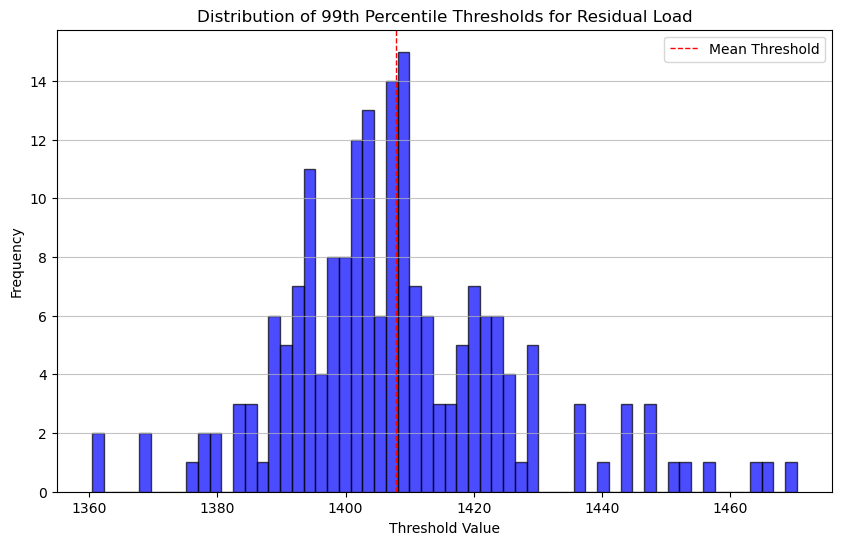

In [9]:
# Test
threshs = []
for esm_run in ts_datasets.ESM_run.values:
    ts_datasets_tst = ts_datasets.sel(ESM_run=esm_run)
    # RL_tst = ts_datasets_tst['Residual_load_adj']
    RL_tst = ts_datasets_tst['Residual_load']
    threshold_tst = np.quantile(RL_tst.values.flatten(), thresh_perc)
    threshs.append(threshold_tst)

# Plot the thresholds as a distribution
plt.figure(figsize=(10, 6))
plt.hist(threshs, bins=60, color='blue', alpha=0.7, edgecolor='black')
plt.title(f'Distribution of {int(thresh_perc * 100)}th Percentile Thresholds for Residual Load')
plt.xlabel('Threshold Value')
plt.ylabel('Frequency')
plt.grid(axis='y', alpha=0.75)
plt.axvline(np.mean(threshs), color='red', linestyle='dashed', linewidth=1, label='Mean Threshold')
plt.legend()
plt.show()

In [10]:
# Time series of "True" when threshold is exceeded, "False" otherwise

exceed_bool_1 = xr.where(RL > threshold_week, True, False)
exceed_bool_7 = xr.where(RL_mov_avg_7 > threshold_week, True, False)
exceed_bool_14 = xr.where(RL_mov_avg_14 > threshold_week, True, False)

In [11]:
# Look for events without any rolling mean


# Count number of true values overall
count_exceed_1 = exceed_bool_1.sum(dim='time').sum(dim='ESM_run')
count_exceed_1.values
# exceed_bool_1.time
# np.zeros_like(exceed_bool_1, dtype=int)

array(7125)

### Days above threshold (dat) 

- Take each day as its own event (not really events but just days above threshold)

In [12]:
# 1) Extract the flat indices where mask is True
run_idx, time_idx = np.nonzero(exceed_bool_1.values)
n_dat = run_idx.size

# 2) Create a flat counter 1…n_dat
labels = np.arange(1, n_dat + 1, dtype=int)

# 3) Scatter them back into an integer array of same shape
dat = np.zeros_like(exceed_bool_1.values, dtype=int)
dat[run_idx, time_idx] = labels

# wrap back into an xarray
dat = xr.DataArray(
    dat,
    coords=exceed_bool_1.coords,
    dims=exceed_bool_1.dims,
    name="dat"
)

n_dat = n_dat
dat

<xarray.DataArray 'dat' (ESM_run: 194, time: 3650)> Size: 6MB
array([[   0,    0,    0, ...,    0,    0,    0],
       [   0,    0,    0, ...,    0,    0,    0],
       [   0,    0,    0, ...,    0,    0,    0],
       ...,
       [   0,    0,    0, ...,    0,    0, 6978],
       [   0,    0,    0, ...,    0, 7045,    0],
       [   0,    0,    0, ...,    0,    0,    0]])
Coordinates:
    crs       int64 8B 4326
    gridtype  <U6 24B 'lonlat'
  * time      (time) datetime64[ns] 29kB 2015-01-01 2015-01-02 ... 2024-12-31
    ESM       (ESM_run) <U13 10kB 'ACCESS-CM2' 'ACCESS-CM2' ... 'SMARD'
    run       (ESM_run) <U12 9kB 'r1i1p1f1' 'r4i1p1f1' ... 'r8i1p1f2' 'hist'
  * ESM_run   (ESM_run) <U23 18kB 'ACCESS-CM2_r1i1p1f1' ... 'SMARD_hist'
    country   float64 8B 9.0
    period    (ESM_run) <U4 3kB 'week' 'week' 'week' ... 'week' 'week' 'wwd'
    doy       (time) int64 29kB 1 2 3 4 5 6 7 8 ... 359 360 361 362 363 364 365

In [13]:
# 1) Extract the flat indices where mask is True
run_idx, time_idx = np.nonzero(exceed_bool_7.values)
n_dat_7 = run_idx.size

# 2) Create a flat counter 1…n_dat_7
labels = np.arange(1, n_dat_7 + 1, dtype=int)

# 3) Scatter them back into an integer array of same shape
dat_7 = np.zeros_like(exceed_bool_7.values, dtype=int)
dat_7[run_idx, time_idx] = labels

# wrap back into an xarray
dat_7 = xr.DataArray(
    dat_7,
    coords=exceed_bool_7.coords,
    dims=exceed_bool_7.dims,
    name="dat_7"
)

n_dat_7 = n_dat_7
dat_7

<xarray.DataArray 'dat_7' (ESM_run: 194, time: 3650)> Size: 6MB
array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]])
Coordinates:
    crs       int64 8B 4326
    gridtype  <U6 24B 'lonlat'
  * time      (time) datetime64[ns] 29kB 2015-01-01 2015-01-02 ... 2024-12-31
    ESM       (ESM_run) <U13 10kB 'ACCESS-CM2' 'ACCESS-CM2' ... 'SMARD'
    run       (ESM_run) <U12 9kB 'r1i1p1f1' 'r4i1p1f1' ... 'r8i1p1f2' 'hist'
  * ESM_run   (ESM_run) <U23 18kB 'ACCESS-CM2_r1i1p1f1' ... 'SMARD_hist'
    country   float64 8B 9.0
    period    (ESM_run) <U4 3kB 'week' 'week' 'week' ... 'week' 'week' 'wwd'
    doy       (time) int64 29kB 1 2 3 4 5 6 7 8 ... 359 360 361 362 363 364 365

In [14]:
# 1) Extract the flat indices where mask is True
run_idx, time_idx = np.nonzero(exceed_bool_14.values)
n_dat_14 = run_idx.size

# 2) Create a flat counter 1…n_dat_14
labels = np.arange(1, n_dat_14 + 1, dtype=int)

# 3) Scatter them back into an integer array of same shape
dat_14 = np.zeros_like(exceed_bool_14.values, dtype=int)
dat_14[run_idx, time_idx] = labels

# wrap back into an xarray
dat_14 = xr.DataArray(
    dat_14,
    coords=exceed_bool_14.coords,
    dims=exceed_bool_14.dims,
    name="dat_14"
)

n_dat_14 = n_dat_14
dat_14

<xarray.DataArray 'dat_14' (ESM_run: 194, time: 3650)> Size: 6MB
array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]])
Coordinates:
    crs       int64 8B 4326
    gridtype  <U6 24B 'lonlat'
  * time      (time) datetime64[ns] 29kB 2015-01-01 2015-01-02 ... 2024-12-31
    ESM       (ESM_run) <U13 10kB 'ACCESS-CM2' 'ACCESS-CM2' ... 'SMARD'
    run       (ESM_run) <U12 9kB 'r1i1p1f1' 'r4i1p1f1' ... 'r8i1p1f2' 'hist'
  * ESM_run   (ESM_run) <U23 18kB 'ACCESS-CM2_r1i1p1f1' ... 'SMARD_hist'
    country   float64 8B 9.0
    period    (ESM_run) <U4 3kB 'week' 'week' 'week' ... 'week' 'week' 'wwd'
    doy       (time) int64 29kB 1 2 3 4 5 6 7 8 ... 359 360 361 362 363 364 365

### Events with rolling mean of 1 above threshold (events_vl) = events with varying length 

In [15]:
# Look for events without any rolling mean

events_vl = np.zeros_like(exceed_bool_1, dtype=int)

# Starting value for the labels
current_label = 1
counter = 0
for run in exceed_bool_1.ESM_run.values:
    run_data = exceed_bool_1.sel(ESM_run=run)
    # Only label this section
    labeled_segment, num_features = ndimage.label(run_data.values)

    if num_features > 0:
        labeled_segment[labeled_segment > 0] += current_label - 1
        current_label += num_features

    # Save the label to the result array
    events_vl[counter] = labeled_segment
    counter += 1

n_events_vl = current_label - 1
n_events_vl



4455

In [16]:
def LEE_detection(events, n_events, t=RL['time'].values, dur = 7, minDuration=1):
    LEE_records = []

    for i in range(len(RL.ESM_run)):
        for ev in range(1, n_events + 1):
            event_duration = (events[i] == ev).sum()
            if event_duration < minDuration:
                continue
            print(f"Processing event {ev} for run {i+1}/{len(RL.ESM_run)}")

            end_idx = np.where(events[i] == ev)[0][0]
            start_idx = end_idx - dur + 1

            date_start = t[start_idx]
            date_end = t[end_idx]

            LEE_start = np.where(t == date_start)[0][0]
            LEE_end = np.where(t == date_end)[0][0]

            RL_run = RL.sel(ESM_run=RL.ESM_run[i]).values
            RL_LEE = RL_run[LEE_start:LEE_end + 1]
            LEE_peak = np.argmax(RL_LEE)

            record = {
                'date_start': date_start,
                'date_end': date_end,
                'date_peak': date_start + LEE_peak,
                # 'date_start_old': RL['old_time'][i][LEE_start].values,
                # 'date_end_old': RL['old_time'][i][LEE_end].values,
                # 'date_peak_old': RL['old_time'][i][LEE_start + LEE_peak].values,
                'index_start': LEE_start,
                'index_end': LEE_end,
                'index_peak': LEE_start + LEE_peak,
                'duration': len(RL_LEE),
                'RL_max': RL_LEE[LEE_peak],
                'RL_mean': RL_LEE.mean(),
                'RL_var': np.sqrt(RL_LEE.var()),
                'RL_cumulative': RL_LEE.sum(),
                'event': ev,
                'ESM': str(RL.ESM[i].values),
                'ESM_run': str(RL.ESM_run[i].values),
                'year': RL.time.dt.year[start_idx].values,
                'doy' : RL.doy[start_idx].values#,
                # 'winter': RL.winter_year[start_idx].values,
                # 'day_of_winter': RL.day_of_winter[start_idx].values
            }

            # # Optional additional metrics if available
            # # (you could generalize this to loop over var names too)
            # for var in ['prod', 'demand', 'pot']:
            #     try:
            #         var_data = RL[var].sel(ESM_run=RL.ESM_run[i]).values[LEE_start:LEE_end + 1]
            #         record[f'{var}_max'] = var_data.max()
            #         record[f'{var}_mean'] = var_data.mean()
            #         record[f'{var}_var'] = np.sqrt(var_data.var())
            #         record[f'{var}_cumulative'] = var_data.sum()
            #     except KeyError:
            #         pass  # Variable doesn't exist, skip

            LEE_records.append(record)

    return pd.DataFrame(LEE_records)


In [17]:
LEE_dat = LEE_detection(dat, n_dat, dur = 1)

Processing event 1 for run 1/194
Processing event 2 for run 1/194
Processing event 3 for run 1/194
Processing event 4 for run 1/194
Processing event 5 for run 1/194
Processing event 6 for run 1/194
Processing event 7 for run 1/194
Processing event 8 for run 1/194
Processing event 9 for run 1/194
Processing event 10 for run 1/194
Processing event 11 for run 1/194
Processing event 12 for run 1/194
Processing event 13 for run 1/194
Processing event 14 for run 1/194
Processing event 15 for run 1/194
Processing event 16 for run 1/194
Processing event 17 for run 1/194
Processing event 18 for run 1/194
Processing event 19 for run 1/194
Processing event 20 for run 1/194
Processing event 21 for run 1/194
Processing event 22 for run 1/194
Processing event 23 for run 1/194
Processing event 24 for run 1/194
Processing event 25 for run 1/194
Processing event 26 for run 1/194
Processing event 27 for run 1/194
Processing event 28 for run 1/194
Processing event 29 for run 1/194
Processing event 30 for

In [18]:
# LEE_dat.to_csv('/climca/people/onennecke/model_output/LEE_detection/LEE_dat.csv', index=False)
# LEE_dat.to_csv('/climca/people/onennecke/model_output/LEE_detection/not_bc_adj/LEE_dat.csv', index=False)
LEE_dat.to_csv('/climca/people/onennecke/model_output/LEE_detection/LEE_dat_99.csv', index=False)


LEE_dat

,date_start,date_end,date_peak,index_start,index_end,index_peak,duration,RL_max,RL_mean,RL_var,RL_cumulative,event,ESM,ESM_run,year,doy
0,2015-11-04,2015-11-04,2015-11-04,307,307,307,1,1412.958383,1412.958383,0.0,1412.958383,1,ACCESS-CM2,ACCESS-CM2_r1i1p1f1,2015,308
1,2015-12-16,2015-12-16,2015-12-16,349,349,349,1,1475.052717,1475.052717,0.0,1475.052717,2,ACCESS-CM2,ACCESS-CM2_r1i1p1f1,2015,350
2,2015-12-17,2015-12-17,2015-12-17,350,350,350,1,1416.195216,1416.195216,0.0,1416.195216,3,ACCESS-CM2,ACCESS-CM2_r1i1p1f1,2015,351
3,2016-12-12,2016-12-12,2016-12-12,710,710,710,1,1461.989287,1461.989287,0.0,1461.989287,4,ACCESS-CM2,ACCESS-CM2_r1i1p1f1,2016,346
4,2016-12-22,2016-12-22,2016-12-22,720,720,720,1,1418.734000,1418.734000,0.0,1418.734000,5,ACCESS-CM2,ACCESS-CM2_r1i1p1f1,2016,356
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7120,2022-01-10,2022-01-10,2022-01-10,2564,2564,2564,1,1430.526000,1430.526000,0.0,1430.526000,7121,SMARD,SMARD_hist,2022,10
7121,2022-01-25,2022-01-25,2022-01-25,2579,2579,2579,1,1433.217750,1433.217750,0.0,1433.217750,7122,SMARD,SMARD_hist,2022,25
7122,2023-11-30,2023-11-30,2023-11-30,3253,3253,3253,1,1446.194500,1446.194500,0.0,1446.194500,7123,SMARD,SMARD_hist,2023,334
7123,2024-12-11,2024-12-11,2024-12-11,3629,3629,3629,1,1425.075500,1425.075500,0.0,1425.075500,7124,SMARD,SMARD_hist,2024,345


In [19]:
LEE_dat_7 = LEE_detection(dat_7, n_dat_7, dur = 7)

Processing event 1 for run 2/194
Processing event 2 for run 2/194
Processing event 3 for run 2/194
Processing event 4 for run 2/194
Processing event 5 for run 2/194
Processing event 6 for run 5/194
Processing event 7 for run 5/194
Processing event 8 for run 5/194
Processing event 9 for run 5/194
Processing event 10 for run 5/194
Processing event 11 for run 7/194
Processing event 12 for run 8/194
Processing event 13 for run 8/194
Processing event 14 for run 8/194
Processing event 15 for run 8/194
Processing event 16 for run 8/194
Processing event 17 for run 8/194
Processing event 18 for run 8/194
Processing event 19 for run 8/194
Processing event 20 for run 9/194
Processing event 21 for run 9/194
Processing event 22 for run 9/194
Processing event 23 for run 9/194
Processing event 24 for run 10/194
Processing event 25 for run 10/194
Processing event 26 for run 10/194
Processing event 27 for run 10/194
Processing event 28 for run 10/194
Processing event 29 for run 10/194
Processing event 

In [21]:
# If the date_start is the the next day from the line before and they are the same ESM_run they should get the same event number
new_run = LEE_dat_7['ESM_run'].ne(LEE_dat_7['ESM_run'].shift())
not_consecutive = (LEE_dat_7['date_start'] - LEE_dat_7['date_start'].shift()) != pd.Timedelta(days=1)

# Combine them — whenever either is True, that row is the start of a new event
is_new_event = new_run | not_consecutive

# 4. Cum-sum that to get a 1-based event ID
LEE_dat_7['event'] = is_new_event.cumsum()
LEE_dat_7

,date_start,date_end,date_peak,index_start,index_end,index_peak,duration,RL_max,RL_mean,RL_var,RL_cumulative,event,ESM,ESM_run,year,doy
0,2019-12-25,2019-12-31,2019-12-25 00:00:00.000000002,1818,1824,1820,7,1498.476085,1448.320399,51.319314,10138.242794,1,ACCESS-CM2,ACCESS-CM2_r4i1p1f1,2019,359
1,2019-12-26,2020-01-01,2019-12-26 00:00:00.000000001,1819,1825,1820,7,1498.476085,1458.250430,36.329759,10207.753007,1,ACCESS-CM2,ACCESS-CM2_r4i1p1f1,2019,360
2,2019-12-27,2020-01-02,2019-12-27 00:00:00.000000000,1820,1826,1820,7,1498.476085,1450.806570,34.585543,10155.645988,1,ACCESS-CM2,ACCESS-CM2_r4i1p1f1,2019,361
3,2019-12-28,2020-01-03,2019-12-28 00:00:00.000000000,1821,1827,1821,7,1481.201221,1446.000833,29.606690,10122.005831,1,ACCESS-CM2,ACCESS-CM2_r4i1p1f1,2019,362
4,2019-12-29,2020-01-04,2019-12-29 00:00:00.000000000,1822,1828,1822,7,1475.517794,1442.291951,26.419364,10096.043657,1,ACCESS-CM2,ACCESS-CM2_r4i1p1f1,2019,363
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
739,2017-01-17,2017-01-23,2017-01-17 00:00:00.000000006,746,752,752,7,1566.878000,1435.642714,128.531035,10049.499000,251,SMARD,SMARD_hist,2017,17
740,2017-01-18,2017-01-24,2017-01-18 00:00:00.000000006,747,753,753,7,1627.713750,1446.692500,140.670297,10126.847500,251,SMARD,SMARD_hist,2017,18
741,2017-01-19,2017-01-25,2017-01-19 00:00:00.000000005,748,754,753,7,1627.713750,1460.625714,148.305625,10224.380000,251,SMARD,SMARD_hist,2017,19
742,2017-01-20,2017-01-26,2017-01-20 00:00:00.000000004,749,755,753,7,1627.713750,1442.885821,150.878919,10100.200750,251,SMARD,SMARD_hist,2017,20


In [25]:
LEE_dat_7.to_csv('/climca/people/onennecke/model_output/LEE_detection/LEE_dat_7.csv', index=False)
# LEE_dat_7.to_csv('/climca/people/onennecke/model_output/LEE_detection/not_bc_adj/LEE_dat_7.csv', index=False)

LEE_dat_7

,date_start,date_end,date_peak,index_start,index_end,index_peak,duration,RL_max,RL_mean,RL_var,RL_cumulative,event,ESM,ESM_run,year,doy
0,2016-12-20,2016-12-26,2016-12-20 00:00:00.000000004,718,724,722,7,1423.669022,1352.595015,74.060716,9468.165104,1,ACCESS-CM2,ACCESS-CM2_r1i1p1f1,2016,354
1,2016-12-21,2016-12-27,2016-12-21 00:00:00.000000003,719,725,722,7,1423.669022,1363.985879,60.214536,9547.901154,1,ACCESS-CM2,ACCESS-CM2_r1i1p1f1,2016,355
2,2017-12-01,2017-12-07,2017-12-01 00:00:00.000000005,1064,1070,1069,7,1430.660269,1336.117805,54.253834,9352.824634,2,ACCESS-CM2,ACCESS-CM2_r1i1p1f1,2017,335
3,2018-01-18,2018-01-24,2018-01-18 00:00:00.000000002,1112,1118,1114,7,1414.239417,1340.338876,85.408675,9382.372131,3,ACCESS-CM2,ACCESS-CM2_r1i1p1f1,2018,18
4,2018-01-19,2018-01-25,2018-01-19 00:00:00.000000001,1113,1119,1114,7,1414.239417,1322.396611,123.223309,9256.776279,3,ACCESS-CM2,ACCESS-CM2_r1i1p1f1,2018,19
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10388,2018-02-03,2018-02-09,2018-02-03 00:00:00.000000004,1128,1134,1132,7,1500.555000,1328.324714,160.849718,9298.273000,2388,SMARD,SMARD_hist,2018,34
10389,2018-02-04,2018-02-10,2018-02-04 00:00:00.000000003,1129,1135,1132,7,1500.555000,1328.256464,160.901258,9297.795250,2388,SMARD,SMARD_hist,2018,35
10390,2019-01-18,2019-01-24,2019-01-18 00:00:00.000000006,1477,1483,1483,7,1568.968250,1336.794464,141.330911,9357.561250,2389,SMARD,SMARD_hist,2019,18
10391,2019-01-19,2019-01-25,2019-01-19 00:00:00.000000005,1478,1484,1483,7,1568.968250,1360.466000,140.394451,9523.262000,2389,SMARD,SMARD_hist,2019,19


In [22]:
# find the index of the row with the highest RL_cumulative in each event
idx = LEE_dat_7.groupby('event')['RL_cumulative'].idxmax()

# select only those rows
LEE_dat_7_max_cum_RL = LEE_dat_7.loc[idx].reset_index(drop=True)
LEE_dat_7_max_cum_RL


,date_start,date_end,date_peak,index_start,index_end,index_peak,duration,RL_max,RL_mean,RL_var,RL_cumulative,event,ESM,ESM_run,year,doy
0,2019-12-26,2020-01-01,2019-12-26 00:00:00.000000001,1819,1825,1820,7,1498.476085,1458.250430,36.329759,10207.753007,1,ACCESS-CM2,ACCESS-CM2_r4i1p1f1,2019,360
1,2018-12-18,2018-12-24,2018-12-18 00:00:00.000000003,1446,1452,1449,7,1465.527389,1427.373605,21.264614,9991.615233,2,CESM2,CESM2_LE2-1001_001,2018,352
2,2022-12-21,2022-12-27,2022-12-21 00:00:00.000000005,2909,2915,2914,7,1457.836572,1411.804491,37.901447,9882.631434,3,CESM2,CESM2_LE2-1021_002,2022,355
3,2016-12-26,2017-01-01,2016-12-26 00:00:00.000000006,724,730,730,7,1469.746656,1422.635637,59.374617,9958.449462,4,CESM2,CESM2_LE2-1031_002,2016,360
4,2021-12-20,2021-12-26,2021-12-20 00:00:00.000000004,2543,2549,2547,7,1471.313795,1451.544454,16.766022,10160.811180,5,CESM2,CESM2_LE2-1031_002,2021,354
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
246,2016-01-25,2016-01-31,2016-01-25 00:00:00.000000003,389,395,392,7,1499.505278,1435.855721,46.541871,10050.990050,247,UKESM1-0-LL,UKESM1-0-LL_r8i1p1f2,2016,25
247,2022-12-08,2022-12-14,2022-12-08 00:00:00.000000006,2896,2902,2902,7,1462.013044,1415.905022,59.955255,9911.335152,248,UKESM1-0-LL,UKESM1-0-LL_r8i1p1f2,2022,342
248,2022-12-19,2022-12-25,2022-12-19 00:00:00.000000004,2907,2913,2911,7,1527.405071,1419.756149,68.613606,9938.293045,249,UKESM1-0-LL,UKESM1-0-LL_r8i1p1f2,2022,353
249,2015-01-19,2015-01-25,2015-01-19 00:00:00.000000001,18,24,19,7,1567.507000,1432.481214,160.806691,10027.368500,250,SMARD,SMARD_hist,2015,19


In [ ]:
# LEE_dat_7_max_cum_RL.to_csv('/climca/people/onennecke/model_output/LEE_detection/not_bc_adj/LEE_dat_7_selection.csv', index=False)
LEE_dat_7_max_cum_RL.to_csv('/climca/people/onennecke/model_output/LEE_detection/LEE_dat_7_selection.csv', index=False)
# LEE_dat_7_max_cum_RL.to_csv('/climca/people/onennecke/model_output/LEE_detection/LEE_dat_99_7_selection.csv', index=False)


In [23]:
LEE_dat_14 = LEE_detection(dat_14, n_dat_14, dur = 14)

Processing event 1 for run 14/194
Processing event 2 for run 14/194
Processing event 3 for run 14/194
Processing event 4 for run 14/194
Processing event 5 for run 14/194
Processing event 6 for run 14/194
Processing event 7 for run 14/194
Processing event 8 for run 14/194
Processing event 9 for run 17/194
Processing event 10 for run 17/194
Processing event 11 for run 17/194
Processing event 12 for run 17/194
Processing event 13 for run 20/194
Processing event 14 for run 20/194
Processing event 15 for run 21/194
Processing event 16 for run 23/194
Processing event 17 for run 23/194
Processing event 18 for run 23/194
Processing event 19 for run 23/194
Processing event 20 for run 24/194
Processing event 21 for run 24/194
Processing event 22 for run 24/194
Processing event 23 for run 24/194
Processing event 24 for run 24/194
Processing event 25 for run 24/194
Processing event 26 for run 24/194
Processing event 27 for run 24/194
Processing event 28 for run 24/194
Processing event 29 for run 2

In [24]:
# If the date_start is the the next day from the line before and they are the same ESM_run they should get the same event number
new_run = LEE_dat_14['ESM_run'].ne(LEE_dat_14['ESM_run'].shift())
not_consecutive = (LEE_dat_14['date_start'] - LEE_dat_14['date_start'].shift()) != pd.Timedelta(days=1)

# Combine them — whenever either is True, that row is the start of a new event
is_new_event = new_run | not_consecutive

# 4. Cum-sum that to get a 1-based event ID
LEE_dat_14['event'] = is_new_event.cumsum()
# LEE_dat_14

In [ ]:
LEE_dat_14.to_csv('/climca/people/onennecke/model_output/LEE_detection/LEE_dat_14.csv', index=False)
# LEE_dat_14.to_csv('/climca/people/onennecke/model_output/LEE_detection/not_bc_adj/LEE_dat_14.csv', index=False)

LEE_dat_14

,date_start,date_end,date_peak,index_start,index_end,index_peak,duration,RL_max,RL_mean,RL_var,RL_cumulative,event,ESM,ESM_run,year,doy
0,2021-12-20,2022-01-02,2021-12-20 00:00:00.000000009,2543,2556,2552,14,1470.723622,1410.675457,68.013824,19749.456403,1,CESM2,CESM2_LE2-1091_005,2021,354
1,2021-12-21,2022-01-03,2021-12-21 00:00:00.000000013,2544,2557,2557,14,1472.735236,1423.063377,62.141411,19922.887283,1,CESM2,CESM2_LE2-1091_005,2021,355
2,2021-12-22,2022-01-04,2021-12-22 00:00:00.000000012,2545,2558,2557,14,1472.735236,1427.511480,62.314111,19985.160719,1,CESM2,CESM2_LE2-1091_005,2021,356
3,2021-12-23,2022-01-05,2021-12-23 00:00:00.000000011,2546,2559,2557,14,1472.735236,1428.382786,62.601654,19997.359003,1,CESM2,CESM2_LE2-1091_005,2021,357
4,2021-12-24,2022-01-06,2021-12-24 00:00:00.000000010,2547,2560,2557,14,1472.735236,1418.220840,68.061988,19855.091764,1,CESM2,CESM2_LE2-1091_005,2021,358
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
121,2018-01-04,2018-01-17,2018-01-04 00:00:00.000000000,1098,1111,1098,14,1557.809953,1446.746620,136.970540,20254.452673,28,UKESM1-0-LL,UKESM1-0-LL_r2i1p1f2,2018,4
122,2018-01-05,2018-01-18,2018-01-05 00:00:00.000000008,1099,1112,1107,14,1549.792861,1440.318585,133.679640,20164.460186,28,UKESM1-0-LL,UKESM1-0-LL_r2i1p1f2,2018,5
123,2018-01-06,2018-01-19,2018-01-06 00:00:00.000000007,1100,1113,1107,14,1549.792861,1437.459670,132.177990,20124.435385,28,UKESM1-0-LL,UKESM1-0-LL_r2i1p1f2,2018,6
124,2018-01-07,2018-01-20,2018-01-07 00:00:00.000000006,1101,1114,1107,14,1549.792861,1426.619062,129.460460,19972.666872,28,UKESM1-0-LL,UKESM1-0-LL_r2i1p1f2,2018,7


In [26]:
# find the index of the row with the highest RL_cumulative in each event
idx = LEE_dat_14.groupby('event')['RL_cumulative'].idxmax()

# select only those rows
LEE_dat_14_max_cum_RL = LEE_dat_14.loc[idx].reset_index(drop=True)
LEE_dat_14_max_cum_RL

,date_start,date_end,date_peak,index_start,index_end,index_peak,duration,RL_max,RL_mean,RL_var,RL_cumulative,event,ESM,ESM_run,year,doy
0,2021-12-23,2022-01-05,2021-12-23 00:00:00.000000011,2546,2559,2557,14,1472.735236,1428.382786,62.601654,19997.359003,1,CESM2,CESM2_LE2-1091_005,2021,357
1,2021-12-28,2022-01-10,2021-12-28 00:00:00.000000006,2551,2564,2557,14,1472.735236,1415.767270,69.429600,19820.741784,2,CESM2,CESM2_LE2-1091_005,2021,362
2,2021-11-29,2021-12-12,2021-11-29 00:00:00.000000002,2522,2535,2524,14,1455.700408,1418.844636,30.191865,19863.824902,3,CESM2,CESM2_LE2-1121_007,2021,333
3,2022-01-03,2022-01-16,2022-01-03 00:00:00.000000007,2557,2570,2564,14,1509.666341,1431.188614,45.605930,20036.640595,4,CESM2,CESM2_LE2-1151_008,2022,3
4,2020-01-21,2020-02-03,2020-01-21 00:00:00.000000001,1845,1858,1846,14,1447.303963,1410.695806,27.134645,19749.741285,5,CESM2,CESM2_LE2-1161_009,2020,21
5,2017-01-02,2017-01-15,2017-01-02 00:00:00.000000007,731,744,738,14,1491.099887,1417.241748,52.494885,19841.384465,6,CESM2,CESM2_LE2-1181_010,2017,2
6,2016-12-30,2017-01-12,2016-12-30 00:00:00.000000001,728,741,729,14,1518.537733,1466.044762,34.226032,20524.626667,7,CESM2,CESM2_LE2-1191_010,2016,364
7,2018-01-12,2018-01-25,2018-01-12 00:00:00.000000012,1106,1119,1118,14,1470.406787,1421.154938,37.228233,19896.169132,8,CESM2,CESM2_LE2-1231_002,2018,12
8,2016-12-19,2017-01-01,2016-12-19 00:00:00.000000010,717,730,727,14,1472.301849,1427.281197,36.316901,19981.936761,9,CESM2,CESM2_LE2-1231_013,2016,353
9,2017-12-31,2018-01-13,2017-12-31 00:00:00.000000003,1094,1107,1097,14,1475.731820,1436.364351,25.252205,20109.100912,10,CESM2,CESM2_LE2-1231_019,2017,365


In [ ]:
# LEE_dat_14_max_cum_RL.to_csv('/climca/people/onennecke/model_output/LEE_detection/not_bc_adj/LEE_dat_14_selection.csv', index=False)
LEE_dat_14_max_cum_RL.to_csv('/climca/people/onennecke/model_output/LEE_detection/LEE_dat_14_selection.csv', index=False)
# LEE_dat_14_max_cum_RL.to_csv('/climca/people/onennecke/model_output/LEE_detection/LEE_dat_99_14_selection.csv', index=False)


### Event detection for variable length

In [27]:
def LEE_detection_vl(events, n_events, t=RL['time'].values, minDuration=1):
    LEE_records = []

    for i in range(len(RL.ESM_run)):
        for ev in range(1, n_events + 1):
            event_duration = (events[i] == ev).sum()
            if event_duration < minDuration:
                continue

            start_idx = np.where(events[i] == ev)[0][0]
            end_idx = np.where(events[i] == ev)[0][-1]

            date_start = t[start_idx]
            date_end = t[end_idx]

            LEE_start = np.where(t == date_start)[0][0]
            LEE_end = np.where(t == date_end)[0][0]

            RL_run = RL.sel(ESM_run=RL.ESM_run[i]).values
            RL_LEE = RL_run[LEE_start:LEE_end + 1]
            LEE_peak = np.argmax(RL_LEE)

            record = {
                'date_start': date_start,
                'date_end': date_end,
                'date_peak': date_start + LEE_peak,
                # 'date_start_old': RL['old_time'][i][LEE_start].values,
                # 'date_end_old': RL['old_time'][i][LEE_end].values,
                # 'date_peak_old': RL['old_time'][i][LEE_start + LEE_peak].values,
                'index_start': LEE_start,
                'index_end': LEE_end,
                'index_peak': LEE_start + LEE_peak,
                'duration': len(RL_LEE),
                'RL_max': RL_LEE[LEE_peak],
                'RL_mean': RL_LEE.mean(),
                'RL_var': np.sqrt(RL_LEE.var()),
                'RL_cumulative': RL_LEE.sum(),
                'event': ev,
                'ESM': str(RL.ESM[i].values),
                'ESM_run': str(RL.ESM_run[i].values),
                'year': RL.time.dt.year[start_idx].values,
                'doy' : RL.doy[start_idx].values#,
                # 'winter': RL.winter_year[start_idx].values,
                # 'day_of_winter': RL.day_of_winter[start_idx].values
            }

            # # Optional additional metrics if available
            # # (you could generalize this to loop over var names too)
            # for var in ['prod', 'demand', 'pot']:
            #     try:
            #         var_data = RL[var].sel(ESM_run=RL.ESM_run[i]).values[LEE_start:LEE_end + 1]
            #         record[f'{var}_max'] = var_data.max()
            #         record[f'{var}_mean'] = var_data.mean()
            #         record[f'{var}_var'] = np.sqrt(var_data.var())
            #         record[f'{var}_cumulative'] = var_data.sum()
            #     except KeyError:
            #         pass  # Variable doesn't exist, skip

            LEE_records.append(record)

    return pd.DataFrame(LEE_records)

In [28]:
LEE_vl = LEE_detection_vl(events_vl, n_events_vl)

In [33]:
# LEE_vl.to_csv('/climca/people/onennecke/model_output/LEE_detection/not_bc_adj/LEE_vl.csv', index=False)
# LEE_vl.to_csv('/climca/people/onennecke/model_output/LEE_detection/LEE_vl.csv', index=False)
LEE_vl.to_csv('/climca/people/onennecke/model_output/LEE_detection/LEE_vl_99.csv', index=False)


In [29]:
LEE_vl

,date_start,date_end,date_peak,index_start,index_end,index_peak,duration,RL_max,RL_mean,RL_var,RL_cumulative,event,ESM,ESM_run,year,doy
0,2015-11-04,2015-11-04,2015-11-04,307,307,307,1,1412.958383,1412.958383,0.000000,1412.958383,1,ACCESS-CM2,ACCESS-CM2_r1i1p1f1,2015,308
1,2015-12-16,2015-12-17,2015-12-16,349,350,349,2,1475.052717,1445.623966,29.428751,2891.247933,2,ACCESS-CM2,ACCESS-CM2_r1i1p1f1,2015,350
2,2016-12-12,2016-12-12,2016-12-12,710,710,710,1,1461.989287,1461.989287,0.000000,1461.989287,3,ACCESS-CM2,ACCESS-CM2_r1i1p1f1,2016,346
3,2016-12-22,2016-12-22,2016-12-22,720,720,720,1,1418.734000,1418.734000,0.000000,1418.734000,4,ACCESS-CM2,ACCESS-CM2_r1i1p1f1,2016,356
4,2016-12-24,2016-12-25,2016-12-24,722,723,722,2,1423.669022,1423.127042,0.541980,2846.254084,5,ACCESS-CM2,ACCESS-CM2_r1i1p1f1,2016,358
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4450,2021-11-16,2021-11-16,2021-11-16,2509,2509,2509,1,1438.162500,1438.162500,0.000000,1438.162500,4451,SMARD,SMARD_hist,2021,320
4451,2022-01-10,2022-01-10,2022-01-10,2564,2564,2564,1,1430.526000,1430.526000,0.000000,1430.526000,4452,SMARD,SMARD_hist,2022,10
4452,2022-01-25,2022-01-25,2022-01-25,2579,2579,2579,1,1433.217750,1433.217750,0.000000,1433.217750,4453,SMARD,SMARD_hist,2022,25
4453,2023-11-30,2023-11-30,2023-11-30,3253,3253,3253,1,1446.194500,1446.194500,0.000000,1446.194500,4454,SMARD,SMARD_hist,2023,334
